# 02 Baselines: imbalance fixes vs calibration and fairness

**Goal:** compare plain CE, SMOTE-NC, weighted CE, focal loss, other backbones and the post-hoc fixes (S1 prior correction, S2 group thresholds) under one threshold rule (flag the top 10% by risk).
All numbers are on the **validation** split (test is locked until Phase 6): mean over 3 seeds, 95% CI from 1,000 paired stratified bootstrap resamples.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, resolve
from src.data.tensors import load_arrays
from src.eval.metrics import ece_equal_freq

cfg = load_config('configs/train.yaml')
runs = sorted(p for p in resolve(cfg['runs_dir']).glob('*_phase2') if (p / 'results.csv').exists())
RUN = runs[-1]
print('run folder:', RUN.name)
res = pd.read_csv(RUN / 'results.csv').set_index('key')
meta = json.loads((RUN / 'run_meta.json').read_text())
print('git', meta['git_hash'][:10], '| seeds', meta['seeds'], '|', meta['split'])
val, _ = load_arrays(cfg, 'val')

run folder: 20261101T055729Z_phase2
git f8189b2024 | seeds [0, 1, 2] | validation only


## Main table (shared rule: top 10% flagged)

In [2]:
def fmt(k, m, d=3):
    return res.apply(lambda r: f"{r[m]:.{d}f} [{r[m+'_lo']:.{d}f}, {r[m+'_hi']:.{d}f}]", axis=1)
cols = {'auc_roc': 'AUC-ROC', 'auc_pr': 'AUC-PR', 'ks': 'KS', 'recall': 'Recall@10%',
        'dir': 'DIR', 'eod': 'EOD', 'ece': 'ECE', 'worst_group_ece': 'Worst-group ECE',
        'brier': 'Brier'}
main = pd.DataFrame({v: fmt(None, k) for k, v in cols.items()})
main.insert(0, 'arm', res['arm'])
main

,arm,AUC-ROC,AUC-PR,KS,Recall@10%,DIR,EOD,ECE,Worst-group ECE,Brier
key,,,,,,,,,,
a0,A0,"0.744 [0.736, 0.751]","0.220 [0.210, 0.231]","0.364 [0.356, 0.384]","0.312 [0.298, 0.326]","0.940 [0.934, 0.946]","0.083 [0.056, 0.112]","0.007 [0.007, 0.009]","0.014 [0.013, 0.017]","0.069 [0.068, 0.069]"
a1,A1,"0.686 [0.677, 0.695]","0.165 [0.158, 0.174]","0.273 [0.261, 0.291]","0.249 [0.237, 0.262]","0.935 [0.930, 0.942]","0.113 [0.088, 0.139]","0.139 [0.137, 0.141]","0.155 [0.151, 0.158]","0.113 [0.112, 0.114]"
a1b,A1b (SMOTE-NC ratio 1.0),"0.668 [0.659, 0.678]","0.159 [0.151, 0.167]","0.238 [0.227, 0.257]","0.244 [0.231, 0.257]","0.936 [0.931, 0.943]","0.103 [0.076, 0.127]","0.237 [0.235, 0.239]","0.259 [0.255, 0.263]","0.173 [0.171, 0.175]"
a2,A2,"0.746 [0.738, 0.754]","0.221 [0.211, 0.232]","0.366 [0.354, 0.382]","0.320 [0.306, 0.334]","0.946 [0.940, 0.952]","0.076 [0.048, 0.105]","0.333 [0.331, 0.334]","0.350 [0.347, 0.353]","0.198 [0.196, 0.199]"
a3,A3,"0.715 [0.706, 0.724]","0.199 [0.190, 0.209]","0.324 [0.309, 0.340]","0.298 [0.285, 0.311]","0.929 [0.924, 0.936]","0.105 [0.079, 0.132]","0.324 [0.322, 0.326]","0.342 [0.339, 0.344]","0.192 [0.191, 0.194]"
a4,A4,"0.747 [0.738, 0.754]","0.222 [0.212, 0.233]","0.367 [0.353, 0.383]","0.320 [0.305, 0.333]","0.937 [0.931, 0.943]","0.096 [0.069, 0.125]","0.337 [0.336, 0.339]","0.355 [0.352, 0.358]","0.200 [0.198, 0.201]"
a5,A5,"0.744 [0.736, 0.752]","0.219 [0.209, 0.230]","0.365 [0.352, 0.381]","0.319 [0.305, 0.332]","0.943 [0.937, 0.950]","0.089 [0.060, 0.118]","0.389 [0.388, 0.389]","0.393 [0.392, 0.394]","0.221 [0.221, 0.222]"
s1,S1,"0.746 [0.738, 0.754]","0.221 [0.211, 0.232]","0.366 [0.354, 0.382]","0.320 [0.306, 0.334]","0.946 [0.940, 0.952]","0.076 [0.048, 0.105]","0.006 [0.006, 0.008]","0.012 [0.012, 0.015]","0.069 [0.068, 0.069]"
s2_gt,"S2-GT (analysis only: uses gender, not deploya...","0.746 [0.738, 0.754]","0.221 [0.211, 0.232]","0.366 [0.354, 0.382]","0.318 [0.304, 0.332]","0.987 [0.981, 0.993]","0.005 [0.004, 0.032]","0.006 [0.006, 0.008]","0.012 [0.012, 0.015]","0.069 [0.068, 0.069]"


## REF (LightGBM): what changed since the first Phase 2 run

In [3]:
old = sorted(p for p in resolve(cfg['runs_dir']).glob('*_phase2') if (p / 'results.csv').exists())[0]
o = pd.read_csv(old / 'results.csv').set_index('key').loc['ref']
it_old = json.loads((old / 'ref' / 'seed_0' / 'pred_meta.json').read_text())['best_iteration']
it_new = json.loads((RUN / 'ref' / 'seed_0' / 'pred_meta.json').read_text())['best_iteration']
n = res.loc['ref']
pd.DataFrame({'first run': [o['auc_roc'], o['auc_pr'], it_old], 'this run': [n['auc_roc'], n['auc_pr'], it_new]},
             index=['AUC-ROC', 'AUC-PR', 'boosting rounds kept']).round(4)

,first run,this run
AUC-ROC,0.6985,0.7646
AUC-PR,0.1690,0.2410
boosting rounds kept,1.0000,1222.0000


## Imbalance damages calibration; prior correction repairs it

In [4]:
keys = ['a0', 'a1', 'a1b', 'a2', 's1']
cal = res.loc[keys, ['ece', 'worst_group_ece', 'cal_slope', 'cal_intercept', 'brier',
                      'recall_at_0.5', 'flag_rate_at_0.5']].round(4)
cal.columns = ['ECE', 'worst-group ECE', 'cal slope', 'cal intercept', 'Brier',
               'recall at p>0.5 (diagnostic)', 'flag rate at p>0.5 (diagnostic)']
cal

,ECE,worst-group ECE,cal slope,cal intercept,Brier,recall at p>0.5 (diagnostic),flag rate at p>0.5 (diagnostic)
key,,,,,,,
a0,0.0072,0.0140,0.9253,-0.0811,0.0689,0.0047,0.0008
a1,0.1391,0.1548,0.4940,-1.7864,0.1131,0.2733,0.1147
a1b,0.2369,0.2593,0.3959,-2.1550,0.1727,0.4537,0.2481
a2,0.3326,0.3502,1.0051,-2.3809,0.1975,0.6585,0.3264
s1,0.0063,0.0123,1.0051,0.0640,0.0688,0.0024,0.0004


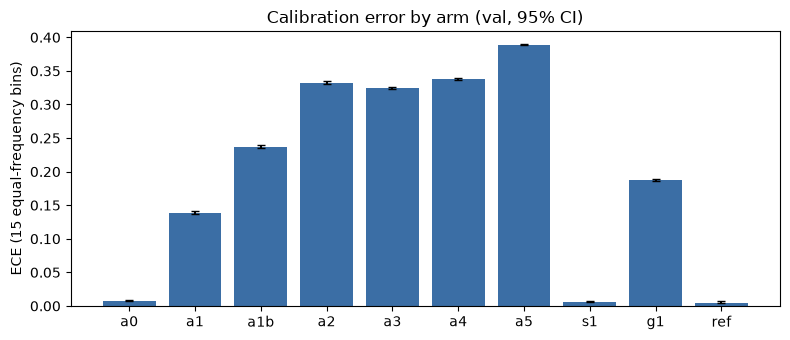

In [5]:
order = [k for k in ['a0','a1','a1b','a2','a3','a4','a5','s1','g1','ref'] if k in res.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
y = res.loc[order, 'ece']
err = [(y - res.loc[order, 'ece_lo']).clip(lower=0), (res.loc[order, 'ece_hi'] - y).clip(lower=0)]
ax.bar(order, y, yerr=err, color='#3b6ea5', capsize=3)
ax.set_ylabel('ECE (15 equal-frequency bins)'); ax.set_title('Calibration error by arm (val, 95% CI)')
plt.tight_layout(); plt.show()

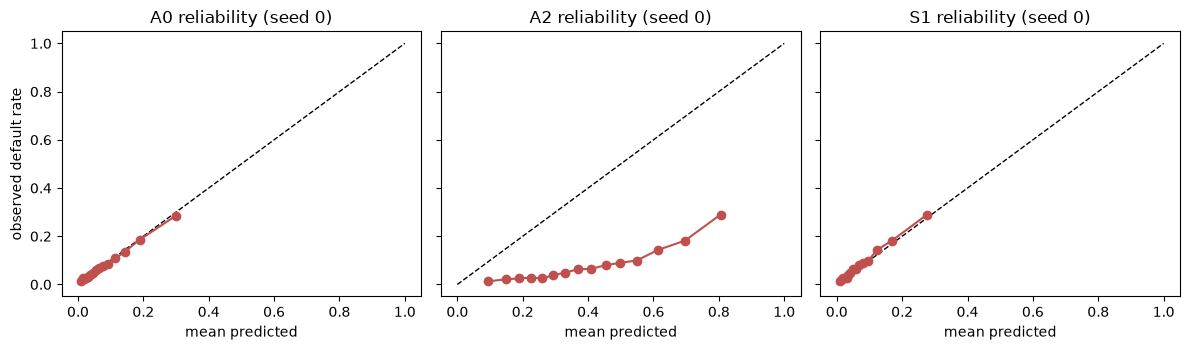

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for a_, key in zip(ax, ['a0', 'a2', 's1']):
    p = np.load(RUN / key / 'seed_0' / 'val_prob.npy')
    order_ = np.argsort(p); idx = np.array_split(order_, 15)
    mp = [p[i].mean() for i in idx]; my = [val.y[i].mean() for i in idx]
    a_.plot([0, 1], [0, 1], 'k--', lw=1); a_.plot(mp, my, 'o-', color='#c0504d')
    a_.set_title(f"{key.upper()} reliability (seed 0)"); a_.set_xlabel('mean predicted')
ax[0].set_ylabel('observed default rate')
plt.tight_layout(); plt.show()

## Does the imbalance fix change group-wise calibration? (A0 per gender)

In [7]:
g = res.loc[['a0', 'a1', 'a1b', 'a2', 's1', 'ref'], ['ece_f', 'ece_m', 'tpr_f', 'tpr_m', 'fpr_f', 'fpr_m']].round(4)
g.columns = ['ECE female', 'ECE male', 'TPR female', 'TPR male', 'FPR female', 'FPR male']
g

,ECE female,ECE male,TPR female,TPR male,FPR female,FPR male
key,,,,,,
a0,0.0064,0.0140,0.2767,0.3598,0.0656,0.1105
a1,0.1313,0.1548,0.2005,0.3137,0.0705,0.1194
a1b,0.2256,0.2593,0.1997,0.3023,0.0709,0.1199
a2,0.3234,0.3502,0.2877,0.3640,0.0674,0.1067
s1,0.0049,0.0123,0.2877,0.3640,0.0674,0.1067
ref,0.0043,0.0083,0.2946,0.3917,0.0632,0.1113


## Fairness at the shared threshold

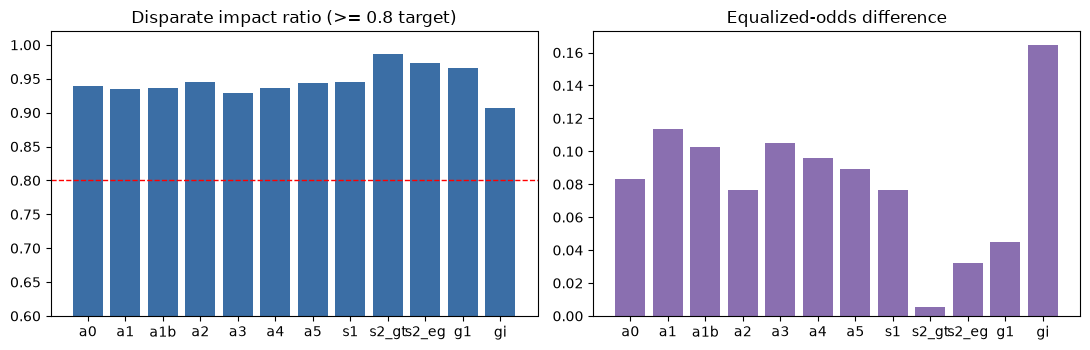

In [8]:
fo = [k for k in ['a0','a1','a1b','a2','a3','a4','a5','s1','s2_gt','s2_eg','g1','gi'] if k in res.index]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(fo, res.loc[fo, 'dir'], color='#3b6ea5'); ax[0].axhline(0.8, color='r', ls='--', lw=1)
ax[0].set_title('Disparate impact ratio (>= 0.8 target)'); ax[0].set_ylim(0.6, 1.02)
ax[1].bar(fo, res.loc[fo, 'eod'], color='#8a6fb0'); ax[1].set_title('Equalized-odds difference')
plt.tight_layout(); plt.show()

## Discrimination vs calibration trade-off per arm

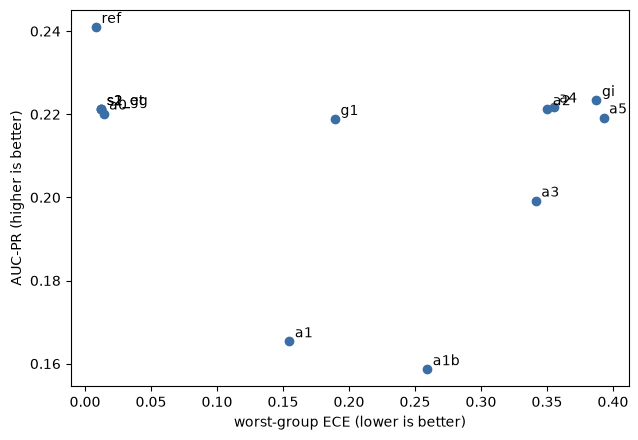

In [9]:
d = res.loc[[k for k in res.index if k not in ('s2_fairlearn',)]]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(d['worst_group_ece'], d['auc_pr'], color='#3b6ea5')
for k, r in d.iterrows(): ax.annotate(k, (r['worst_group_ece'], r['auc_pr']), xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('worst-group ECE (lower is better)'); ax.set_ylabel('AUC-PR (higher is better)')
plt.tight_layout(); plt.show()

## Tuning and training cost

In [10]:
rows = []
for k in ['a0','a1','a1b','a2','a3','a4','a5','g1']:
    t = json.loads((RUN / k / 'tuning.json').read_text())
    s = json.loads((RUN / k / 'summary.json').read_text())['seeds']
    rows.append({'arm': k, 'best tuning AUC-PR': round(t['best_value'], 4),
                 'tuning s': round(t['seconds']), 'mean epochs': np.mean([v['epochs_run'] for v in s.values()]),
                 'mean train s': round(np.mean([v['seconds'] for v in s.values()]), 1),
                 **{p: round(v, 5) for p, v in t['best_params'].items()}})
pd.DataFrame(rows).set_index('arm')

,best tuning AUC-PR,tuning s,mean epochs,mean train s,lr,weight_decay,dropout,emb_dim,focal_gamma
arm,,,,,,,,,
a0,0.2121,38,13.333333,15.5,0.00215,0.00051,0.02824,16.0,NaN
a1,0.1627,74,8.333333,28.4,0.00168,0.00012,0.02432,16.0,NaN
a1b,0.1552,83,10.333333,43.8,0.00072,0.00000,0.01850,16.0,NaN
a2,0.2128,34,12.666667,14.7,0.00265,0.00000,0.25343,16.0,NaN
a3,0.1812,20,27.333333,19.7,0.00250,0.00008,0.24915,NaN,NaN
a4,0.2160,9,10.333333,3.8,0.00274,0.00038,0.08181,NaN,NaN
a5,0.2128,34,16.333333,20.3,0.00091,0.00002,0.22096,16.0,2.58879
g1,0.2115,42,12.333333,18.7,0.00265,0.00000,0.25343,16.0,NaN


## What this shows

All numbers are validation-only (test is locked), mean of 3 seeds, shared rule "flag the top 10%". This is the re-run (run folder shown above) with the revised Optuna sampler (4 random start-up trials, then TPE), arm A1b, the two S2 variants and a corrected REF.

- **Weighted CE inflates probabilities; prior correction repairs it.** A0 (plain CE) is well calibrated (ECE 0.007). A2 (weighted CE) has the same ranking quality (AUC-ROC 0.746 vs 0.744) but ECE 0.333 and a calibration intercept of about -2.4. At the naive p > 0.5 cut-off its recall is 0.66 against 0.005 for A0. S1 (A2 minus the analytic logit shift) restores ECE to 0.006 with identical ranking. At the shared 10% flag rate recall is almost the same for A0 and A2 (0.312 vs 0.320), so the "higher recall" effect only shows at a fixed probability cut-off.
- **SMOTE-NC does not damage calibration more than class weights, even when the prior shift is matched.** A1 (ratio 0.5, shift about 5.7x) has ECE 0.139 and A1b (ratio 1.0, shift about 11.4x) has ECE 0.237, both better than A2 (0.333, shift about 11.4x), so the A1 vs A2 gate item stays failed and A1 is not a like-for-like comparison with A2. Synthetic positives therefore do not move the predicted probabilities as far as the same weight ratio does. Both SMOTE-NC arms discriminate worse (AUC-ROC 0.686 and 0.668 vs 0.746) and stop after 6 to 16 epochs.
- **Group-wise calibration of A0.** A0 is well calibrated for both groups (ECE 0.006 female, 0.014 male), consistent with "group calibration as a byproduct of unconstrained learning" (Liu et al.). The imbalance fixes break it for both groups.
- **Fairness at the shared rule.** Every arm has DIR >= 0.91 (A0 0.940, A2 0.946), so DIR cannot separate arms; the EOD can (A2 0.076, A0 0.083). Women have lower TPR (0.29 vs 0.36) and lower FPR (0.067 vs 0.107). Mitigation arms:
  - **S2-GT** (group thresholds, analysis only, uses gender, validation-optimistic): EOD 0.005, DIR 0.987, AUC unchanged. Thresholds were fit and scored on the same validation split.
  - **S2-EG** (ExponentiatedGradient on the frozen A2 representation, no gender at inference, deployable): EOD 0.033 [0.017, 0.059], DIR 0.973, recall 0.316. Fit on train, scored on validation, so this number is not optimistic. The AUC and ECE columns for S2-EG are those of the S1 score; only its flags change. A first attempt, whose base classifiers flagged about 35% of applicants, collapsed to S1 under the shared rule (EOD 0.073) and is kept in `s2_eg_v1_unmatched/`; the final version sets the base classifier's class weight on train so that it flags about 10%.
  - **G1** (soft group-ECE loss): EOD 0.045, ECE 0.187, DIR 0.966, AUC-PR 0.219 vs 0.221.
  - **S2 fairlearn ThresholdOptimizer** chooses its own operating point (about 34% flagged), so it is shown but not rate-matched.
  - **GI** (gender included, never deployable) has the largest gap (EOD 0.165, DIR 0.906).
- **REF (LightGBM) was mis-trained in the first run and is now fixed.** The earlier AUC-ROC of 0.699 came from early stopping at boosting round 1: LightGBM also tracked the default logloss, which worsens immediately under `scale_pos_weight`. With early stopping on AUC only (lr 0.02, 31 leaves, 1,222 rounds kept, full train set) REF reaches AUC-ROC 0.765 [0.757, 0.773] and AUC-PR 0.241 versus 0.746 [0.738, 0.754] and 0.221 for A2. So on this validation split the tree model is ahead of the TabTransformer by about 0.019 AUC-ROC, with non-overlapping intervals, and the MLP (A4, 0.747) is no better than the transformer. The REF configuration was picked from four settings tried on validation, so treat the gap as indicative, not a final comparison. REF's EOD (0.097) is the largest among the unmitigated models, and its ECE is 0.004 without any correction.
- **Caveats.** Confidence intervals come from 1,000 paired stratified bootstrap resamples of the validation set; bootstrap ECE is biased upward for well-calibrated arms, so the interval for A0, S1 and REF sits slightly above the point estimate. G1's lambda was not tuned.
